# Experiment 03: Embedding size

Card: [exp03_emb_dim.md](../../experiments/exp03_emb_dim.md)


In [1]:
import os
import sys

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import mlflow
import numpy as np
import pandas as pd

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, MODEL_COLORS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle
from ashrae.modeling import MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp03_emb_dim"
if SMOKE:
    EXPERIMENT = "ashrae-mlp-emb-dim-smoke"
    TRAIN = True
    SESSION = None
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 2
    DIMS = [2]
    REFERENCE = (
        "ashrae-mlp-building-smoke",
        None,
        "mlp_4out_emb",
    )  # None: the latest session
    FIGURE = None
else:
    EXPERIMENT = "ashrae-mlp-emb-dim"
    TRAIN = False  # trained in the session below
    SESSION = "2026-10-12 12:25:17"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 10
    DIMS = [2, 4, 8, 12]
    REFERENCE = ("ashrae-mlp-building", "2026-10-12 12:03:22", "mlp_4out_emb")
    FIGURE = "../../figures/exp03_emb_dim.png"
# emb_dim 16 is mlp_4out_emb from exp02
REFERENCE_DIM = 16
ALL_DIMS = [*DIMS, REFERENCE_DIM]
# lgbm_building from baseline exp01, the baseline kept in baseline/baseline_report.md
BASELINE = ("ashrae-baseline-building", "2026-10-11 11:16:15", "lgbm_building")

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

/Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-emb-dim', session 2026-10-12 12:25:17


## Training


In [2]:
if TRAIN:
    df = read_processed()
    n_buildings = int(df.building_id.max()) + 1
    folds = {}
    for fold in FOLD_NAMES:
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "y_val": np.log1p(val_df.meter_reading.to_numpy(dtype="float32")),
            "anomaly": val_df.anomaly.to_numpy(),
        }
    del df
    n_features = X_train.shape[1]
    for fold, d in folds.items():
        train_loader, val_loader = d["loaders"]
        for dim in DIMS:
            model, run_id = experiment.fit(
                lambda: MeterMLP(n_features, n_buildings, emb_dim=dim),
                train_loader,
                val_loader,
                run_name=f"mlp_4out_emb | emb {dim} | {fold}",
                epochs=EPOCHS,
                tags={"fold": fold, "model": "mlp_4out_emb", "emb_dim": str(dim)},
                params={"n_train": N_TRAIN, "n_val": N_VAL, "emb_dim": dim},
            )
            pred, y, anomaly = predict(model, val_loader), d["y_val"], d["anomaly"]
            experiment.log_metrics(
                run_id, {"val_rmsle_clean": rmsle(y[~anomaly], pred[~anomaly])}
            )

## Results


In [3]:
def reference_runs(experiment_name, session, model):
    """Runs of `model` from another notebook's session (the latest one if `session` is None)."""
    runs = mlflow.search_runs(
        experiment_names=[experiment_name], filter_string=f"tags.model = '{model}'"
    )
    return runs[runs["tags.session"] == (session or runs["tags.session"].max())]


reference = reference_runs(*REFERENCE).assign(**{"tags.emb_dim": str(REFERENCE_DIM)})
runs = pd.concat([experiment.runs(), reference])
results = runs.rename(
    columns=lambda c: c.removeprefix("metrics.").removeprefix("tags.")
)
results = results[results.fold.isin(FOLD_NAMES)].assign(
    emb_dim=lambda r: r.emb_dim.astype(int)
)
print(
    f"MLflow session {experiment.session}: {len(results)} runs, with emb_dim {REFERENCE_DIM} from exp02"
)

table = results.pivot(index="emb_dim", columns="fold", values="val_rmsle").loc[
    ALL_DIMS, FOLD_NAMES
]
averages = results.groupby("emb_dim")[
    ["val_rmsle", "val_rmsle_clean", "train_rmsle"]
].mean()
table["average"] = averages.val_rmsle
table["average, clean rows"] = averages.val_rmsle_clean
table["training"] = averages.train_rmsle  # last epoch
display(table.round(3).rename_axis("RMSLE, all rows unless noted"))

baseline_runs = reference_runs(*BASELINE)
baseline = baseline_runs[baseline_runs["tags.fold"].isin(FOLD_NAMES)][
    "metrics.val_rmsle"
].mean()

MLflow session 2026-10-12 12:25:17: 20 runs, with emb_dim 16 from exp02


fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",training
"RMSLE, all rows unless noted",,,,,,,
2,1.466,1.254,1.117,1.134,1.243,0.993,0.891
4,1.440,1.227,1.085,1.111,1.216,0.964,0.861
8,1.434,1.226,1.069,1.108,1.209,0.946,0.839
12,1.421,1.231,1.056,1.103,1.203,0.941,0.830
16,1.420,1.223,1.053,1.105,1.200,0.934,0.826


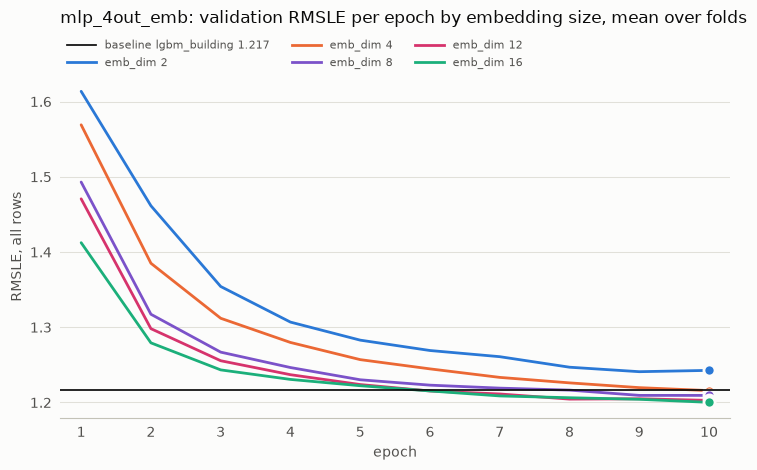

In [ ]:
epochs = np.arange(1, EPOCHS + 1)
INK, TEXT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
# one distinct hue per size so close curves stay apart; 16 keeps mlp_4out_emb's colour from exp02
COLORS = dict(
    zip(
        ALL_DIMS,
        ["#2a78d6", "#eb6834", "#7b52c9", "#d6336c", MODEL_COLORS["mlp_4out_emb"]],
    )
)
curves = {
    dim: np.mean(
        [
            experiment.history(r, "val_rmsle")
            for r in results[results.emb_dim == dim].run_id
        ],
        axis=0,
    )
    for dim in ALL_DIMS
}

fig, ax = plt.subplots(figsize=(7.5, 4.8), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for dim, curve in curves.items():
    ax.plot(epochs, curve, color=COLORS[dim], lw=2, solid_capstyle="round")
    ax.plot(epochs[-1], curve[-1], "o", ms=8, color=COLORS[dim], mec=SURFACE, mew=2)
# LightGBM has no epochs: its fold-average validation score as a reference line, drawn over the curves
ax.hlines(baseline, 0.7, epochs[-1] + 0.3, color=INK, lw=1.25, zorder=5)
ax.set(
    xlabel="epoch",
    xticks=epochs,
    xlim=(0.7, epochs[-1] + 0.3),
    ylabel="RMSLE, all rows",
)
ax.set_title(
    "mlp_4out_emb: validation RMSLE per epoch by embedding size, mean over folds",
    loc="left",
    color=INK,
    pad=38,
)
ax.grid(axis="y", color=GRID, lw=0.75)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, labelcolor=TEXT, length=0, pad=6)
ax.xaxis.label.set_color(TEXT)
ax.yaxis.label.set_color(TEXT)
# Legend under the title: the baseline, then the sizes
handles = [
    Line2D([], [], color=INK, lw=1.25, label=f"baseline {BASELINE[2]} {baseline:.3f}"),
    *(
        Line2D([], [], color=COLORS[dim], lw=2, label=f"emb_dim {dim}")
        for dim in ALL_DIMS
    ),
]
ax.legend(
    handles=handles,
    ncol=3,
    frameon=False,
    fontsize=8,
    handlelength=2.6,
    labelcolor=TEXT,
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    borderaxespad=0.2,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results[
        results.emb_dim.isin(DIMS)
    ].run_id:  # this notebook's runs only
        experiment.client.log_artifact(run_id, FIGURE)